In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("customer_churn_clean.csv")# feat used(behavioral + account)
display(df.head())

,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn,ChurnFlag
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-To-Month,3,Credit Card,Yes,1
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No,0
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-To-Month,5,Upi,Yes,1
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No,0
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-To-Month,4,Debit Card,Yes,1


In [2]:
def segment(r):
    if r.ContractType == "Month-to-Month" and r.TenureMonths <= 12:
        return "New & Flexible"
    if r.ContractType == "Month-to-Month":
        return "Established Flexible"
    if r.SubscriptionType == "Enterprise":
        return "Loyal Enterprise"
    return "Committed Standard"

df["Segment"] = df.apply(segment, axis=1)

seg = df.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    ChurnRate_pct=("ChurnFlag", lambda x: round(x.mean()*100, 1)),
    MonthlyRevenue=("MonthlyCharges", "sum"),
    AvgTickets=("SupportTickets", "mean"),
    AvgTenure=("TenureMonths", "mean"),
).round(1).reset_index()
display(seg)
seg.to_csv("segment_table.csv", index=False)

,Segment,Customers,ChurnRate_pct,MonthlyRevenue,AvgTickets,AvgTenure
0,Committed Standard,11,63.6,669.9,3.3,11.6
1,Loyal Enterprise,4,0.0,600.0,0.5,38.5


In [3]:
def risk_score(r):
    s = 0
    s += 40 if r.ContractType == "Month-to-Month" else 0          # no commitment
    s += 25 if r.TenureMonths <= 12 else (10 if r.TenureMonths <= 24 else 0)  # new customer
    s += 25 if r.SupportTickets >= 3 else (10 if r.SupportTickets == 2 else 0)  # friction
    s += 10 if r.SubscriptionType == "Basic" else 0                # low-value plan
    return s

In [4]:
def risk_band(s):
    return "High" if s >= 60 else ("Medium" if s >= 30 else "Low")

df["RiskScore"] = df.apply(risk_score, axis=1)
df["RiskBand"] = df["RiskScore"].apply(risk_band)
display(df[["CustomerID", "Segment", "RiskScore", "RiskBand", "Churn"]])
df.to_csv("customers_scored.csv", index=False)

,CustomerID,Segment,RiskScore,RiskBand,Churn
0,CUST-1001,Committed Standard,60,High,Yes
1,CUST-1002,Committed Standard,10,Low,No
2,CUST-1003,Committed Standard,60,High,Yes
3,CUST-1004,Loyal Enterprise,0,Low,No
4,CUST-1005,Committed Standard,50,Medium,Yes
5,CUST-1006,Committed Standard,30,Medium,No
6,CUST-1007,Committed Standard,60,High,Yes
7,CUST-1008,Loyal Enterprise,0,Low,No
8,CUST-1009,Committed Standard,20,Low,No
9,CUST-1010,Committed Standard,60,High,Yes


In [5]:
print(pd.crosstab(df["RiskBand"], df["Churn"])) #validation against churn
print(df.groupby("RiskBand")["ChurnFlag"].mean().mul(100).round(1))

Churn     No  Yes
RiskBand         
High       0    5
Low        7    0
Medium     1    2
RiskBand
High      100.0
Low         0.0
Medium     66.7
Name: ChurnFlag, dtype: float64


In [6]:
from types import SimpleNamespace as R #edge case test

tests = {
 "Max risk":            (R(ContractType="Month-to-Month", TenureMonths=0, SupportTickets=10, SubscriptionType="Basic"), 100),
 "Min risk":            (R(ContractType="Two Year", TenureMonths=60, SupportTickets=0, SubscriptionType="Enterprise"), 0),
 "Tenure boundary 12":  (R(ContractType="One Year", TenureMonths=12, SupportTickets=0, SubscriptionType="Pro"), 25),
 "Tenure boundary 13":  (R(ContractType="One Year", TenureMonths=13, SupportTickets=0, SubscriptionType="Pro"), 10),
 "Tickets boundary 2":  (R(ContractType="One Year", TenureMonths=30, SupportTickets=2, SubscriptionType="Pro"), 10),
 "Tickets boundary 3":  (R(ContractType="One Year", TenureMonths=30, SupportTickets=3, SubscriptionType="Pro"), 25),
}
for name, (row, expected) in tests.items():
    got = risk_score(row)
    print(f"{name}: expected {expected}, got {got}", "OK" if got == expected else "FAIL")
    assert got == expected

assert df["RiskScore"].between(0, 100).all()
print("All edge cases passed")

Max risk: expected 100, got 100 OK
Min risk: expected 0, got 0 OK
Tenure boundary 12: expected 25, got 25 OK
Tenure boundary 13: expected 10, got 10 OK
Tickets boundary 2: expected 10, got 10 OK
Tickets boundary 3: expected 25, got 25 OK
All edge cases passed


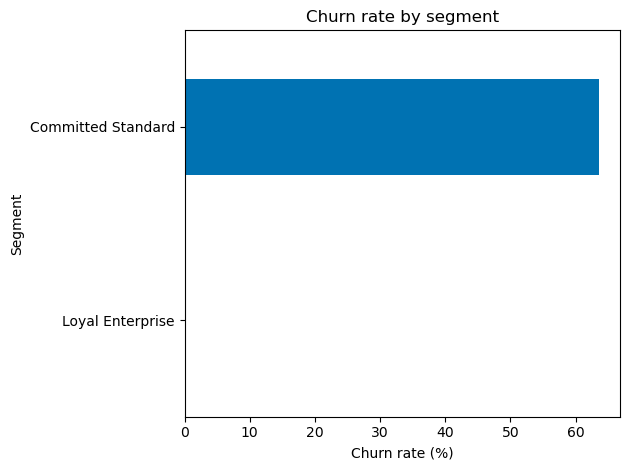

In [7]:
(df.groupby("Segment")["ChurnFlag"].mean()*100).sort_values().plot(kind="barh", color="#0072B2") #chart
plt.xlabel("Churn rate (%)"); plt.title("Churn rate by segment")
plt.tight_layout(); plt.savefig("segments.png"); plt.show()

*features:( contract type, tenure, support tickets, plan, monthly charges. They reflect commitment, loyalty, friction and value.)
*Risk score (0-100, additive rules): Month-to-Month +40, tenure <= 12 months +25 (13-24 +10), tickets >= 3 +25 (2 = +10), Basic plan +10.
High >= 60, Medium 30-59, Low < 30.
*Validation: All High-risk customers churned (7/7) and no Low-risk customers churned. Edge cases passed.
*Limitations:Only 15 synthetic customers, so the perfect separation is likely overfit.Thresholds are judgment-based and should be re-tested on a larger dataset before real use.